In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams, colors
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
import numpy as np
import pickle
import seaborn as sns
import os
# Import helpers from src/rna_seq
from src.rna_seq.helpers import get_sub_dat, plt_ht_map, names_for_genes_pvals

In [2]:
os.getcwd()

'/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/figures/rna_seq/el_exr2'

# Load gene info

In [6]:
glia = pd.read_csv('../../../data/rna_seq/geneIDs/glia.csv')

transmitters = pd.read_csv('../../../data/rna_seq/geneIDs/transmitters.csv')
receptors = pd.read_csv('../../../data/rna_seq/geneIDs/receptors.csv')

VgatedChannels = pd.read_csv('../../../data/rna_seq/geneIDs/VgatedChannels.csv')

neuropeptides = pd.read_csv('../../../data/rna_seq/geneIDs/neuropeptides.csv')

# Load the data

In [7]:
dat_wb = pd.read_csv("../../../data/rna_seq/lowCellSeq.csv")
celltyp_wb = [c.split("_")[0] for c in dat_wb.columns]
dat_wb = dat_wb.iloc[:,[i for i,t in enumerate(celltyp_wb) if ((t == "wholebrain") | (t == "gene"))]]

dat_ExR2 = pd.read_csv("../../../data/rna_seq/ExR2/merged_counts.txt",delimiter = '\t')
dat_EL1 = pd.read_csv("../../../data/rna_seq/EL/SS00027/merged_counts.txt",delimiter = '\t')
dat_EL2 = pd.read_csv("../../../data/rna_seq/EL/SS50573/merged_counts.txt",delimiter = '\t')
dat = dat_EL1
dat = dat.merge(dat_EL2, how = 'left', on = "gene_id")
dat = dat.merge(dat_ExR2, how = 'left', on = "gene_id")
dat = dat.merge(dat_wb, how = 'left', on = "gene_id")

dat = dat.set_index("gene_id", inplace = False)
dat = dat.iloc[:,1:]

dat = dat.drop(['Q5_F01_Sample_MB233B', 'Q5_F02_Sample_MB136B', 
                'Q5_A03_Sample_MB233B', 'Q5_B03_Sample_MB233B',
                'Q5_H02_Sample_MB136B', 'Q5_C03_Sample_MB136B', 'Q5_D03_Sample_MB136B'], axis = 1)

dat = dat.drop(['gene_name_y'], axis = 1)
dat = dat.drop(['gene_name'], axis = 1)

In [8]:
dge_table_MB136B_lowCell = pd.read_csv('../../../data/rna_seq/dge/dge_table_MB136B_wholebrain.csv',delimiter=',')
dge_table_MB233B_lowCell = pd.read_csv('../../../data/rna_seq/dge/dge_table_MB233B_wholebrain.csv',delimiter=',')
dge_table_SS00027_lowCell = pd.read_csv('../../../data/rna_seq/dge/dge_table_SS00027_wholebrain.csv',delimiter=',')
dge_table_SS50573_lowCell = pd.read_csv('../../../data/rna_seq/dge/dge_table_SS50573_wholebrain.csv',delimiter=',')

In [ ]:
# Load the genes of interest
genesOfInt = pd.concat([glia,transmitters,receptors,VgatedChannels,neuropeptides]).reset_index()

MB136B_PVals_lowCell = names_for_genes_pvals(dge_table_MB136B_lowCell,genesOfInt)
MB233B_PVals_lowCell = names_for_genes_pvals(dge_table_MB233B_lowCell,genesOfInt)
SS00027_PVals_lowCell = names_for_genes_pvals(dge_table_SS00027_lowCell,genesOfInt)
SS50573_PVals_lowCell = names_for_genes_pvals(dge_table_SS50573_lowCell,genesOfInt)

combPVals_lowCell = pd.DataFrame({'gene_names':MB136B_PVals_lowCell['gene_names']})
combPVals_lowCell = pd.merge(combPVals_lowCell,MB136B_PVals_lowCell,on='gene_names')
combPVals_lowCell = combPVals_lowCell.rename(columns = {"PValue":"PValue - MB136B"})
combPVals_lowCell = pd.merge(combPVals_lowCell,MB233B_PVals_lowCell,on='gene_names')
combPVals_lowCell = combPVals_lowCell.rename(columns = {"PValue":"PValue - MB233B"})

# combPVals_lowCell = pd.DataFrame({'gene_names': SS00027_PVals_lowCell['gene_names']})
combPVals_lowCell = pd.merge(combPVals_lowCell,SS00027_PVals_lowCell,on='gene_names')
combPVals_lowCell = combPVals_lowCell.rename(columns = {"PValue":"PValue - SS00027"})
combPVals_lowCell = pd.merge(combPVals_lowCell,SS50573_PVals_lowCell,on='gene_names')
combPVals_lowCell = combPVals_lowCell.rename(columns = {"PValue":"PValue - SS50573"})

In [10]:
combPVals_lowCell.head()

,gene_names,PValue - MB136B,PValue - MB233B,PValue - SS00027,PValue - SS50573
0,Vmat,1.221056e-18,5.945915e-19,8.886591e-114,3.868581e-155
1,Ms,1.307578e-15,1.784590e-05,2.853294e-74,1.708449e-19
2,ple,1.094166e-14,4.736361e-13,1.496286e-28,2.903130e-24
3,DAT,9.867360e-13,6.729714e-15,4.736972e-44,5.680767e-47
4,sNPF,2.119045e-11,2.643358e-11,3.093241e-113,7.949329e-194


In [11]:
MB136BMeanVals_lc = dat[[nm for nm in dat.columns if 'MB136B' in nm]].mean(axis=1)
MB233BMeanVals_lc = dat[[nm for nm in dat.columns if 'MB233B' in nm]].mean(axis=1)
SS00027MeanVals_lc = dat[[nm for nm in dat.columns if 'SS00027' in nm]].mean(axis=1)
SS50573MeanVals_lc = dat[[nm for nm in dat.columns if 'SS50573' in nm]].mean(axis=1)
WBMeanVals_lc = dat[[nm for nm in dat.columns if 'wholebrain' in nm]].mean(axis=1)
ctDiffsLowCell = pd.DataFrame({'MB136BDiff':(MB136BMeanVals_lc-WBMeanVals_lc),
                               'MB233BDiff':(MB233BMeanVals_lc-WBMeanVals_lc),
                               'SS00027Diff':(SS00027MeanVals_lc-WBMeanVals_lc),
                               'SS50573Diff':(SS50573MeanVals_lc-WBMeanVals_lc)
                              })
ctDiffsLowCell[ctDiffsLowCell >= 0] = 0
ctDiffsLowCell[ctDiffsLowCell < 0] = 1
ctDiffsLowCell[ctDiffsLowCell == 0] = -1

In [12]:
# Create a lookup table between line names and cell types
lines_to_celltypes = pd.DataFrame({'Line':['SS00027','SS50573',
                                           'MB233B','MB136B',
                                           'wholebrain'],'Cell Type':['EL(line 1)','EL(line 2)',
                                                                      'ExR2 (line 1)','ExR2 (line 2)',
                                                                      'wholebrain']})

dat.columns = [lines_to_celltypes.iloc[i]['Cell Type'] for c in dat.columns for i,l in enumerate(lines_to_celltypes['Line'].values) if l in c]

# Plot the raw data

In [14]:
mask = []
for c in dat.columns:
    if 'EL' in c or 'wholebrain' in c:
        mask.append(True)
    else:
        mask.append(False)
el_dat = dat.loc[:,mask]

In [15]:
line1_mask = el_dat.columns.str.contains('line 1')
line2_mask = el_dat.columns.str.contains('line 2')
wholebrain_mask = el_dat.columns.str.contains('wholebrain')
el_dat_mu = pd.DataFrame({
                          'EL(line 1)':el_dat.loc[:,line1_mask].mean(axis=1),
                          'EL(line 2)':el_dat.loc[:,line2_mask].mean(axis=1),
                          'wholebrain':el_dat.loc[:,wholebrain_mask].mean(axis=1)})

el_dat_mu.head()

,EL(line 1),EL(line 2),wholebrain
gene_id,,,
FBgn0267594,0.000,0.0,0.0
FBgn0259849,0.125,0.0,0.0
FBgn0085494,0.000,0.0,0.0
FBgn0085506,0.000,0.0,0.0
FBgn0259870,0.000,0.0,0.0


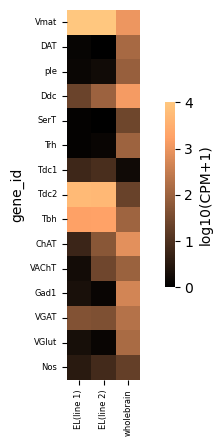

In [ ]:
genes2plt = transmitters

fig,ax = plt_ht_map(genes2plt,el_dat_mu,'CPM',4, cmap='copper')

ax.set_aspect('equal')
ax.tick_params(axis='y') 


FileNotFoundError: [Errno 2] No such file or directory: '../../plots/RNA-Seq/glia.pdf'

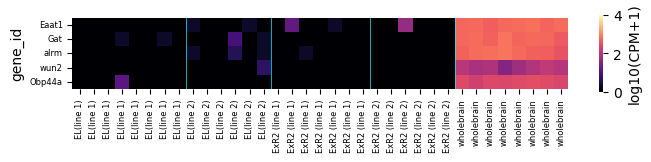

In [ ]:
genes2plt = glia

# fig = plt.figure(figsize=[8,2])
rcParams['svg.fonttype'] = 'none'

# ax = fig.add_subplot()
fig, ax = plt_ht_map(genes2plt,dat,'CPM',4, figsize=[8,2], cmap='magma')
ax.axvline(x=8, color = 'cyan',linewidth=0.5)
ax.axvline(x=14, color = 'cyan',linewidth=0.5)
ax.axvline(x=21, color = 'cyan',linewidth=0.5)
ax.axvline(x=27, color = 'cyan',linewidth=0.5)
ax.set_aspect('equal')
ax.tick_params(axis='y') 



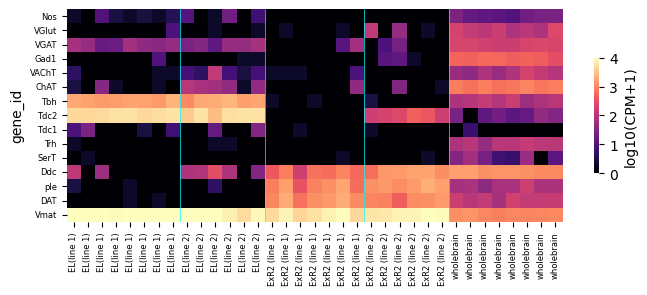

In [ ]:
genes2plt = transmitters.iloc[16::-1,]

fig,ax = plt_ht_map(genes2plt,dat,'CPM',4, figsize=[8,3], cmap='magma')
ax.axvline(x=8, color = 'cyan',linewidth=0.5)
ax.axvline(x=14, color = 'cyan',linewidth=0.5)
ax.axvline(x=21, color = 'cyan',linewidth=0.5)
ax.axvline(x=27, color = 'cyan',linewidth=0.5)
ax.set_aspect('equal')
ax.tick_params(axis='y') 



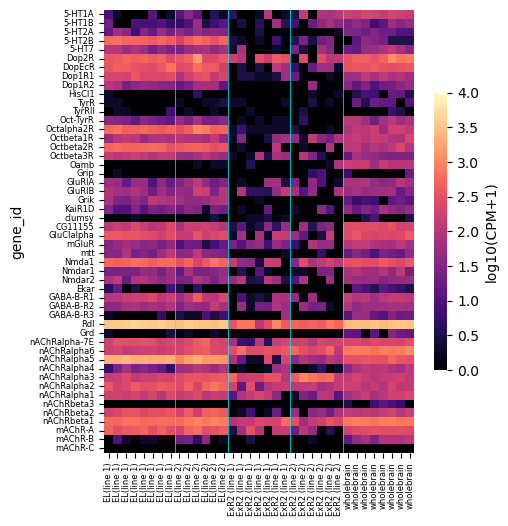

In [ ]:
genes2plt = receptors


rcParams['svg.fonttype'] = 'none'


fig, ax = plt_ht_map(genes2plt,dat,'CPM',4, figsize=[5,12], cmap='magma', cbar_shrink=0.3)
ax.axvline(x=8, color = 'cyan',linewidth=0.5)
ax.axvline(x=14, color = 'cyan',linewidth=0.5)
ax.axvline(x=21, color = 'cyan',linewidth=0.5)
ax.axvline(x=27, color = 'cyan',linewidth=0.5)
ax.set_aspect('equal')
ax.tick_params(axis='y') 

plt.show()
    


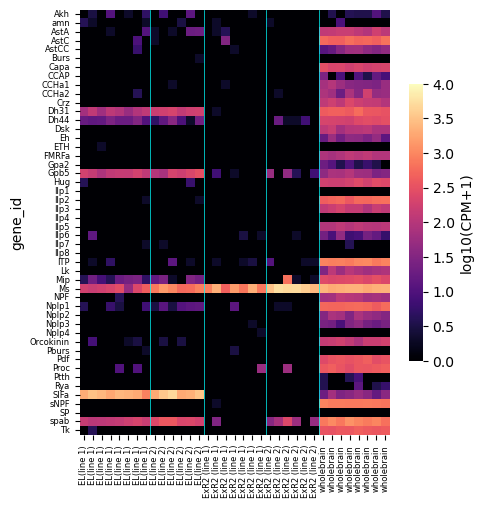

In [ ]:
genes2plt = neuropeptides

# fig = plt.figure(figsize=[5,12])
rcParams['svg.fonttype'] = 'none'

# ax = fig.add_subplot()
fig, ax = plt_ht_map(genes2plt,dat,'CPM',4, figsize=[5,12], cmap='magma', cbar_shrink=0.3)
ax.axvline(x=8, color = 'cyan',linewidth=0.5)
ax.axvline(x=14, color = 'cyan',linewidth=0.5)
ax.axvline(x=21, color = 'cyan',linewidth=0.5)
ax.axvline(x=27, color = 'cyan',linewidth=0.5)
ax.set_aspect('equal')
ax.tick_params(axis='y') 

plt.show()
    


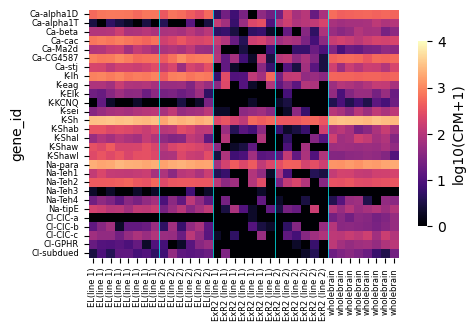

In [ ]:
genes2plt = VgatedChannels

# fig = plt.figure(figsize=[5,12])
rcParams['svg.fonttype'] = 'none'

# ax = fig.add_subplot()
fig, ax = plt_ht_map(genes2plt,dat,'CPM',4, figsize=[5,12], cmap='magma', cbar_shrink=0.2)
ax.axvline(x=8, color = 'cyan',linewidth=0.5)
ax.axvline(x=14, color = 'cyan',linewidth=0.5)
ax.axvline(x=21, color = 'cyan',linewidth=0.5)
ax.axvline(x=27, color = 'cyan',linewidth=0.5)
ax.set_aspect('equal')
ax.tick_params(axis='y') 

plt.show()
    
